# Mapping migration


## Set up
To get started on this notebook, you’ll need to load any libraries you will need.

In [21]:
#!pip install earthpy

In [22]:
### load libraries
import os
import pathlib
import pandas as pd
import geopandas as gpd
import earthpy as et

## Step 1: Create a directory for your data

For this challenge, you will need to download some data to the computer you’re working on. We suggest using the `earthpy` package to manage your downloads, since it encapsulates many best practices as far as:

1.  Where to store your data
2.  Dealing with archived data like .zip files
3.  Avoiding version control problems
4.  Making sure your code works cross-platform
5.  Avoiding duplicate downloads

The code below will help you get started with making a project directory:
1. Replace `my-class-folder` and `my-data-folder` with the (descriptive) names for the folders where you are storing your data for this class
2. The code should have printed out the path to your data files. Check that your data directory exists and has data in it using the terminal or your Finder/File Explorer


> **File structure**
>
> These days, a lot of people find files in their computers by searching for them or
> selecting from a `Bookmarks` or `Recents` list. Even if you don’t use
> it, your computer also keeps files in a **tree** structure of folders.
> Put another way, you can organize and find files by travelling along a
> unique **path**, e.g. `My Drive` \> `Documents` \>
> `My awesome project` \> `A project file`, where each subsequent folder
> is **inside** the previous one. This is convenient because all the
> files for a project can be in the same place, and both people and
> computers can rapidly locate files they want, provided they remember
> the path.
>
> You may notice that when Python prints out a file path like this, the
> folder names are **separated** by a `/` or `\` (depending on your
> operating system). This character is called the **file separator**,
> and it tells you that the next piece of the path is **inside** the
> previous one.

In [31]:
### create your data directory
data_dir = os.path.join(

    ### point to your home directory
    pathlib.Path.home(),

    ### point to folders where your data will live
    'C:/Users/taugi/OneDrive - UCB-O365/GEOG_5463/migration_proj/',
    'C:/Users/taugi/OneDrive - UCB-O365/GEOG_5463/migration_proj/data/',

    ### make a project directory for this assignment
    'migration'
    )

### make the path
os.makedirs(data_dir, exist_ok = True)

In [32]:
data_dir

'C:/Users/taugi/OneDrive - UCB-O365/GEOG_5463/migration_proj/data/migration'

## Step 2: Define your study area – the ecoregions of North America

Next, you will download a shapefile of **ecoregions**. You should be able to see changes in the number of observations of Veery thrush in each ecoregion throughout the year.

You don’t have to use ecoregions to group species observations – you could choose to use political boundaries like countries or states, other natural boundaries like watersheds, or even uniform hexagonal areas as is common in conservation work. We chose ecoregions because we expect the suitability for a species at a particular time of year to be relatively consistent across the region.

The ecoregion data will be available as a **shapefile**. Learn more about shapefiles and vector data [here] (https://www.earthdatascience.org/courses/intro-to-earth-data-science/file-formats/use-spatial-data/use-vector-data/).

### Load the ecoregions into Python
Download and save ecoregion boundaries from the organization RESOLVE:
1. Replace `a_path` with the path your created for your ecoregions file in Step 1.
2. Make a quick plot with `.plot()` to make sure the download worked.

In [24]:
### get url for ecoregions
ecoreg_url = ("https://storage.googleapis.com/"
       "teow2016/Ecoregions2017.zip")

### name the ecoregions directory name and file name
ecoreg_dir = os.path.join(data_dir, "ecoregions")
### make the ecoregions directory
os.makedirs(ecoreg_dir, exist_ok=True)

### join ecoregions shapefile path
ecoreg_path = os.path.join(ecoreg_dir, "ecoregions.shp")
### download the data once
if not os.path.exists(ecoreg_path):
    ecoreg_gdf = gpd.read_file(ecoreg_url)
    ecoreg_gdf.to_file(ecoreg_path)

### open up the ecoregions boundaries
ecoreg_gdf = gpd.read_file(ecoreg_path)
ecoreg_gdf.head()

,OBJECTID,ECO_NAME,BIOME_NUM,BIOME_NAME,REALM,ECO_BIOME_,NNH,ECO_ID,SHAPE_LENG,SHAPE_AREA,NNH_NAME,COLOR,COLOR_BIO,COLOR_NNH,LICENSE,geometry
0,1.0,Adelie Land tundra,11.0,Tundra,Antarctica,AN11,1,117,9.749780,0.038948,Half Protected,#63CFAB,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((158.7141 -69.60657, 158.71264 ..."
1,2.0,Admiralty Islands lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,135,4.800349,0.170599,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((147.28819 -2.57589, 147.2715 -..."
2,3.0,Aegean and Western Turkey sclerophyllous and m...,12.0,"Mediterranean Forests, Woodlands & Scrub",Palearctic,PA12,4,785,162.523044,13.844952,Nature Imperiled,#FF7F7C,#FE0000,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((26.88659 35.32161, 26.88297 35..."
3,4.0,Afghan Mountains semi-desert,13.0,Deserts & Xeric Shrublands,Palearctic,PA13,4,807,15.084037,1.355536,Nature Imperiled,#FA774D,#CC6767,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((65.48655 34.71401, 65.52872 34..."
4,5.0,Ahklun and Kilbuck Upland Tundra,11.0,Tundra,Nearctic,NE11,1,404,22.590087,8.196573,Half Protected,#4C82B6,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((-160.26404 58.64097, -160.2673..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

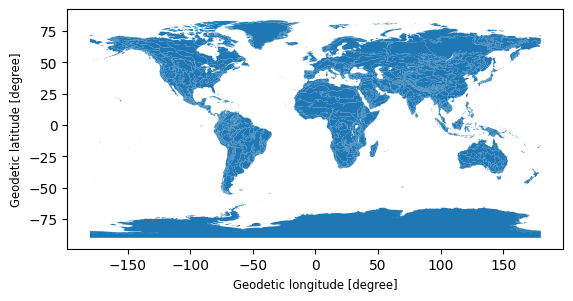

In [25]:
### plot the ecoregions quickly to check download
ecoreg_gdf.plot()

## Step 3: Load the species observation data

For this challenge, you will use a database called the [Global Biodiversity Information Facility (GBIF)](https://www.gbif.org/). GBIF compiles species observation data all over the world, and includes everything from museum specimens to photos taken by community members in their backyards. We’ve compiled some sample data in the same format that you will get from GBIF.

You will use the earthpy package to download some data that we have already compiled for your from GBIF.

In [26]:
### gbif url
gbif_url = "https://ndownloader.figshare.com/files/58363291"

### use earthpy to download the data
earthpy_download_dir = et.data.get_data(
    url = gbif_url,
    replace = True,
    verbose = True
)
print(earthpy_download_dir)

C:\Users\taugi\earth-analytics\data\gbif_veery.csv


In [27]:
### save the path where the gbif data downloaded to
gbif_path = pathlib.Path(earthpy_download_dir)
gbif_path

WindowsPath('C:/Users/taugi/earth-analytics/data/gbif_veery.csv')

### Step 3A: Load GBIF data
1. Look at the beginning of the file you downloaded using the code below. What do you think the **delimiter** is?
2. Run the following code cell. What happens?
3. Uncomment and modify the parameters of `pd.read_csv()` below until your data loads successfully and you have only the columns you want.

In [28]:
### load the GBIF data
gbif_df = pd.read_csv(
    gbif_path, 
    # set delimiter and index column
    delimiter = '\t',
    index_col = 'gbifID',
    # subset the columns to load
    usecols = ['gbifID', 'decimalLatitude', 'decimalLongitude','month']
)

### check out the data
gbif_df.head()

,decimalLatitude,decimalLongitude,month
gbifID,,,
4158712344,41.913700,-82.509200,5
4923515059,41.852812,-87.611721,5
4923522410,41.852812,-87.611721,9
4923520798,41.852812,-87.611721,5
4923520314,41.880356,-87.630134,9


### Step 3B: Convert the GBIF data to a GeoDataFrame

To plot the GBIF data, we need to convert it to a `GeoDataFrame` first. This will make some special geospatial operations from `geopandas` available, such as spatial joins and plotting.

1. Replace `your_dataframe` with the name of the `DataFrame` you just got from GBIF
2. Replace `longitude_column_name` and `latitude_column_name` with column names from your `DataFrame`
3. Run the code to get a `GeoDataFrame` of the GBIF data.

In [29]:
### convert the dataframe to a geodataframe
gbif_gdf = (
    gpd.GeoDataFrame(
        gbif_df, 

        ### set geometry for geodataframe from lat/lon of GBIF record
        geometry = gpd.points_from_xy(
            gbif_df.decimalLongitude, # this first
            gbif_df.decimalLatitude), # this second

        ### set the coordinate reference system
        crs="EPSG:4326") # esri standard for lat/lon, dd
    
    ### select the desired columns
    [['month', 'geometry']]
)

### check out the geodataframe
gbif_gdf

,month,geometry
gbifID,,
4158712344,5,POINT (-82.5092 41.9137)
4923515059,5,POINT (-87.61172 41.85281)
4923522410,9,POINT (-87.61172 41.85281)
4923520798,5,POINT (-87.61172 41.85281)
4923520314,9,POINT (-87.63013 41.88036)
...,...,...
4423534780,9,POINT (-75.1254 40.0626)
4524632357,6,POINT (-89.8049 44.6967)
4173211734,5,POINT (-82.4753 42.0478)


## Wrap up Steps 1-3

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [30]:
%store gbif_gdf ecoreg_gdf

Stored 'gbif_gdf' (GeoDataFrame)
Stored 'ecoreg_gdf' (GeoDataFrame)


Finally, be sure to `Restart` and `Run all` to make sure your notebook
works all the way through!